# Where should the tag look? Pixel priors from one empty-room frame

**Question.** Can a large pretrained model, shown one frame of the empty room and given a query, tell the server which pixels the tag should read, *before any person has been seen*? If so, the tag could be given a useful code immediately, and retasked for another query ("chair" instead of "person") with no new data.

**Priors** (`experiments/relevance_prior.py`; each is a 120×160 map of the baseline frame):
* `grad_person`, `grad_chair`: input-gradient relevance (SmoothGrad, 16 noisy copies) of the COCO detector's evidence for the class: how much a small change of each pixel would move the score. Same frame, same model, two queries.
* `vit_attn`: supervised ViT-B/16 (ImageNet), last-layer class-token attention, averaged over heads.
* `dino_attn`: DINO ViT-S/8 (self-supervised, known for clean object attention), the same.
* `edges`: gradient magnitude of the frame, a control with no learned model.
* `uniform`, `random`: no prior.

**Reality** (from the labels; used only to score): `heads`, a smoothed density of annotated head points; `discrim`, the per-pixel AUC of |frame − baseline| between person and empty frames (where a person's presence actually changes the pixel). A code built from the top of `discrim` is an oracle: it uses the labels.

**Rooms**: `A` (`training`, `test1`, `test3`) and `A2`, the rearranged room (`training_seats`, `test2`). Baseline: the room's first frame that is labelled empty, scored ≤ 0.3 by the detector, and not corrupted.

**Three tests.** (1) Do the maps point where people are? (2) A 96-pixel code with no labels at all (bit = more than 15 gray levels from the baseline, score = bits set): AUC on the room's frames. (3) The adaptive loop (detector teacher, PIROPO stream, one pass) with the tag's candidate pixels restricted to a prior's top 300: does it start better from few labels?

**Findings in brief** (first run, 2026-11-11). A negative result, and an informative one.
1. **Pixels chosen by a pretrained model are worse than pixels chosen at random.** With no labels, a 96-pixel code from the model priors scores AUC 0.65–0.75 in room A and 0.70–0.74 in the rearranged room, against 0.81–0.83 (A) and 0.78–0.88 (A2) for a uniform lattice or random pixels. The oracle that uses the labels gets 0.95 and 0.88.
2. **The maps partly find where people are, but that is not what makes a pixel useful.** In the rearranged room the "person" gradient and DINO attention do follow the head density (Spearman ρ 0.49 and 0.40, and 1.6–1.8× more head density at their pixels than at random ones). In room A they do not (|ρ| < 0.12): people there mostly appear at the back of the room, by the door, where the models see nothing of interest. And in both rooms every model prior is *negatively* correlated with the pixels whose change actually signals a person (ρ −0.06 to −0.20).
3. **The two rooms fail in different ways** (figure at the end of section 3). The models put their pixels on chairs, desks, screens and edges. In room A those pixels are quiet but in the wrong place: on the foreground furniture, while people walk at the back of the room, so 40% of person frames set none of the "person" gradient's bits. In room A2 they overlap the seats but are noisy: furniture and edges change past the tolerance with nobody there, so an empty frame sets 10–17 of their 96 bits, against 4.6 for a uniform lattice. Spreading the pixels evenly covers the room and lands few of them on edges.
4. **No help to the online loop either.** Restricting the learner's candidates to a prior's top 300 pixels gives balanced accuracy 0.77–0.81 over the stream, against 0.80–0.83 for 300 uniform or random pixels and 0.81–0.82 for the full 1,200-pixel lattice.
5. **Query conditioning is visible but not useful yet.** "person" and "chair" give different maps from the same frame and model, but the "chair" code is not consistently worse at detecting people (room A 0.65 against 0.75; room A2 0.74 against 0.70).

So the idea, as tested, does not work: relevance or attention on one empty frame is a map of *salient objects*, while a good presence code needs pixels that are (a) where people appear, (b) stable when nobody is there, and (c) spread out. The maps carry some of (a) in one of the two rooms and work against (b) and (c).

In [ ]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve())); sys.path.insert(0, str(Path('.').resolve()))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from relevance_prior import pick, PRIORS
from semwisp.metrics import summary, balanced_accuracy

BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.edgecolor': '#b5b4ae', 'font.size': 10,
                     'axes.titlesize': 11, 'axes.titleweight': 'bold', 'lines.linewidth': 2})
pd.set_option('display.precision', 3)
RES = Path('../results/relevance_prior')
M = np.load(RES / 'maps.npz')
zero = pd.read_csv(RES / 'zero.csv')
LABEL = dict(grad_person='detector gradient: "person"', grad_chair='detector gradient: "chair"', vit_attn='ViT-B/16 attention',
             dino_attn='DINO ViT-S/8 attention', edges='edges (no model)', uniform='uniform lattice', random='random (5 draws)',
             discrim='oracle: uses the labels', lattice='full 4-px lattice (1,200)')

## 0. The method in pictures

**A** is the experiment of section 3: no labels at all. One empty frame goes through a frozen pretrained model; its relevance map picks 96 pixels; the tag's bit for each is "this pixel is more than 15 gray levels from the empty frame"; the server's score is the number of bits set. Uniform, random and an oracle that uses the labels go through the same pipeline with a different pixel picker. **B** is section 4: the prior (room A's map) only narrows the candidates to its top 300 pixels, at least 3 apart, and the online learner, taught by the detector, still chooses the 96 itself.

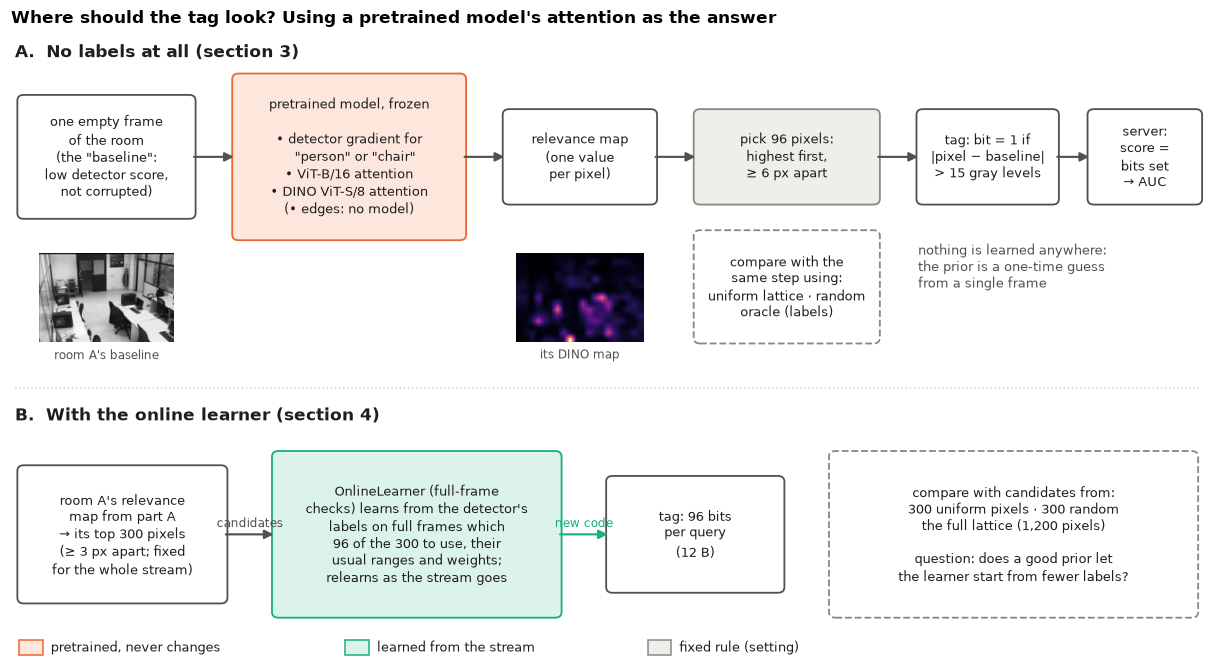

In [2]:
from matplotlib.patches import FancyBboxPatch
INK, MUTED = '#1f1e1c', '#52514e'
TINT = dict(aqua='#dcf3ea', orange='#fde7dd', gray='#efeeea', blue='#e2ecfa')

def box(ax, x, y, w, h, text, fc='white', ec=MUTED, lw=1.2, fs=8.8, ls='-'):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.02,rounding_size=0.08', fc=fc, ec=ec, lw=lw, ls=ls))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=fs, color=INK, linespacing=1.3)

def arrow(ax, x0, y0, x1, y1, text=None, color=MUTED, fs=8, off=(0, 0.06), ls='-'):
    ax.annotate('', (x1, y1), (x0, y0), arrowprops=dict(arrowstyle='-|>', color=color, lw=1.4, ls=ls, shrinkA=0,
                                                        shrinkB=0, mutation_scale=12))
    if text:
        ax.text((x0 + x1) / 2 + off[0], (y0 + y1) / 2 + off[1], text, ha='center', va='bottom', fontsize=fs, color=color)

def prior_diagram():
    fig, ax = plt.subplots(figsize=(14, 7.4))
    ax.set_xlim(0, 15); ax.set_ylim(-0.6, 8.2); ax.axis('off')
    # A. no labels
    ax.text(0.05, 7.85, 'A.  No labels at all (section 3)', fontsize=11, fontweight='bold', color=INK)
    box(ax, 0.1, 5.6, 2.2, 1.7, 'one empty frame\nof the room\n(the "baseline":\nlow detector score,\nnot corrupted)')
    ax.imshow(M['A/baseline'], cmap='gray', extent=(0.35, 2.05, 3.85, 5.1), aspect='auto', zorder=3)
    arrow(ax, 2.3, 6.45, 2.8, 6.45)
    box(ax, 2.8, 5.3, 2.9, 2.3, 'pretrained model, frozen\n\n• detector gradient for\n   "person" or "chair"\n• ViT-B/16 attention\n• DINO ViT-S/8 attention\n'
        '(• edges: no model)', fc=TINT['orange'], ec=ORANGE)
    arrow(ax, 5.7, 6.45, 6.2, 6.45)
    box(ax, 6.2, 5.8, 1.9, 1.3, 'relevance map\n(one value\nper pixel)', fc='white')
    ax.imshow(M['A/dino_attn'], cmap='magma', extent=(6.35, 7.95, 3.85, 5.1), aspect='auto', zorder=3)
    arrow(ax, 8.1, 6.45, 8.6, 6.45)
    ax.text(1.2, 3.75, 'room A\'s baseline', ha='center', va='top', fontsize=8, color=MUTED)
    ax.text(7.15, 3.75, 'its DINO map', ha='center', va='top', fontsize=8, color=MUTED)
    box(ax, 8.6, 5.8, 2.3, 1.3, 'pick 96 pixels:\nhighest first,\n≥ 6 px apart', fc=TINT['gray'], ec=GRAY)
    box(ax, 8.6, 3.85, 2.3, 1.55, 'compare with the\nsame step using:\nuniform lattice · random\noracle (labels)', fc='white', ec=GRAY, ls='--', fs=8.2)
    arrow(ax, 10.9, 6.45, 11.4, 6.45)
    box(ax, 11.4, 5.8, 1.75, 1.3, 'tag: bit = 1 if\n|pixel − baseline|\n> 15 gray levels', fc='white', fs=8.3)
    arrow(ax, 13.15, 6.45, 13.55, 6.45)
    box(ax, 13.55, 5.8, 1.4, 1.3, 'server:\nscore =\nbits set\n→ AUC', fc='white', fs=8.3)
    ax.text(11.4, 5.25, 'nothing is learned anywhere:\nthe prior is a one-time guess\nfrom a single frame',
            fontsize=8.3, color=MUTED, va='top', linespacing=1.3)
    # B. online
    ax.plot([0.05, 14.95], [3.2, 3.2], color='#d6d5d0', lw=1, ls=':')
    ax.text(0.05, 2.75, 'B.  With the online learner (section 4)', fontsize=11, fontweight='bold', color=INK)
    box(ax, 0.1, 0.2, 2.6, 1.9, 'room A\'s relevance\nmap from part A\n→ its top 300 pixels\n(≥ 3 px apart; fixed\nfor the whole stream)', fc='white')
    arrow(ax, 2.7, 1.15, 3.3, 1.15, 'candidates', off=(0, 0.06))
    box(ax, 3.3, 0.0, 3.6, 2.3, 'OnlineLearner (full-frame\nchecks) learns from the detector\'s\nlabels on full frames which\n96 of the 300 to use, their\n'
        'usual ranges and weights;\nrelearns as the stream goes', fc=TINT['aqua'], ec=AQUA)
    arrow(ax, 6.9, 1.15, 7.5, 1.15, 'new code', off=(0, 0.06), color=AQUA)
    box(ax, 7.5, 0.35, 2.2, 1.6, 'tag: 96 bits\nper query\n(12 B)', fc='white')
    box(ax, 10.3, 0.0, 4.6, 2.3, 'compare with candidates from:\n300 uniform pixels · 300 random\nthe full lattice (1,200 pixels)\n\n'
        'question: does a good prior let\nthe learner start from fewer labels?', fc='white', ec=GRAY, ls='--', fs=8.3)
    # legend
    for k, (c, t, x) in enumerate([(ORANGE, 'pretrained, never changes', 0.1), (AQUA, 'learned from the stream', 4.2),
                                   (GRAY, 'fixed rule (setting)', 8.0)]):
        ax.add_patch(plt.Rectangle((x, -0.55), 0.3, 0.22, fc=TINT[{ORANGE: 'orange', AQUA: 'aqua', GRAY: 'gray'}[c]], ec=c))
        ax.text(x + 0.4, -0.44, t, fontsize=8.5, va='center', color=INK)
    ax.set_title('Where should the tag look? Using a pretrained model\'s attention as the answer', loc='left')
    return fig

prior_diagram(); plt.show()


## 1. The maps, and the 96 pixels each would choose

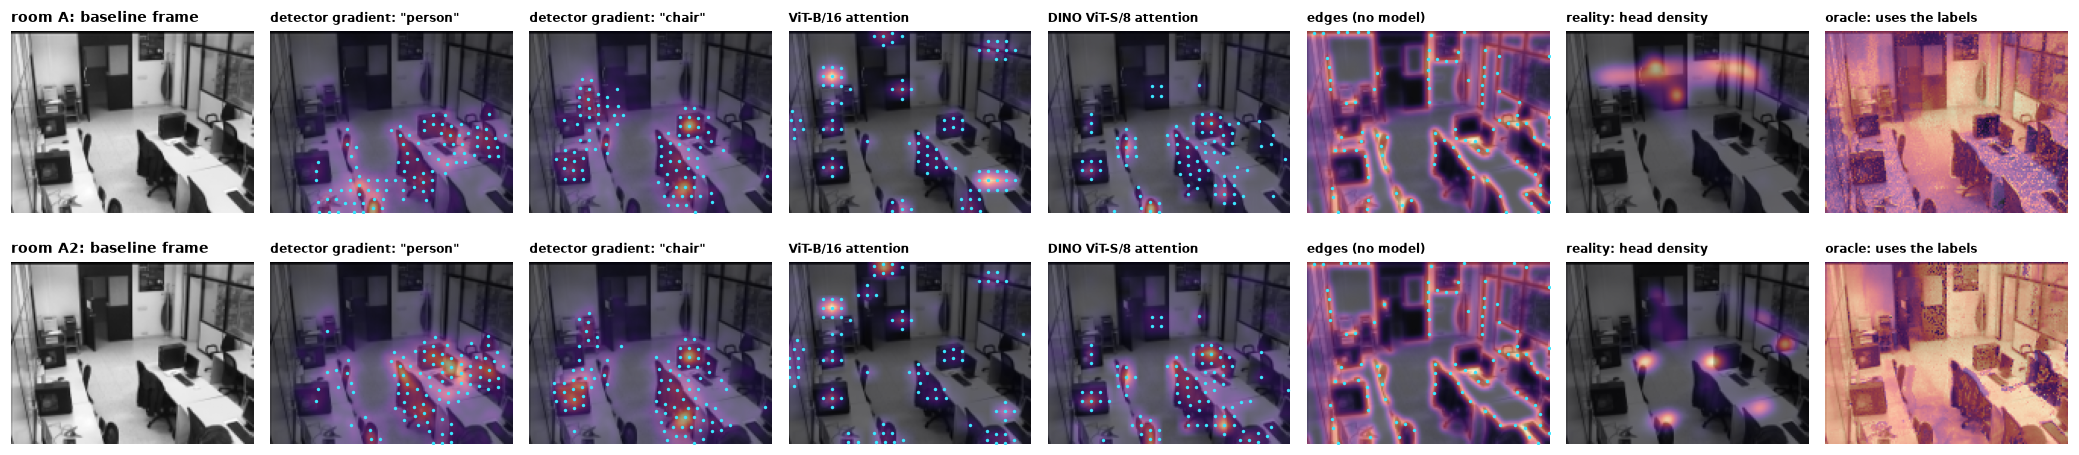

In [3]:
names = ['grad_person', 'grad_chair', 'vit_attn', 'dino_attn', 'edges', 'heads', 'discrim']
fig, axs = plt.subplots(2, len(names) + 1, figsize=(19, 4.6))
for r, room in enumerate(['A', 'A2']):
    base = M[f'{room}/baseline']
    axs[r, 0].imshow(base, cmap='gray'); axs[r, 0].set_title(f'room {room}: baseline frame', fontsize=9, loc='left')
    for c, n in enumerate(names, 1):
        ax = axs[r, c]
        ax.imshow(base, cmap='gray'); ax.imshow(M[f'{room}/{n}'], cmap='magma', alpha=0.6)
        if n not in ('heads', 'discrim'):
            px = pick(M[f'{room}/{n}'], 96); ax.scatter(px[:, 1], px[:, 0], s=5, c='#39e6ff', linewidths=0)
        ax.set_title(LABEL.get(n, {'heads': 'reality: head density', 'discrim': 'reality: discriminative pixels'}.get(n)), fontsize=8, loc='left')
for ax in axs.ravel():
    ax.axis('off')
plt.tight_layout(); plt.show()

**What the maps show.** Cyan dots are the 96 pixels each prior would give the tag (at least 6 pixels apart).
* The two detector gradients and DINO attention light up the chairs and desks in the foreground; "chair" and "person" differ in detail (the "person" map reaches further onto the floor between the desks) but cover the same furniture.
* ViT-B/16 attention picks a few high-contrast objects: screens, the window and the door frame. Edges trace every outline.
* The reality maps disagree with all of them. In room A the annotated heads are mostly along the back of the room, by the door and windows; in room A2 they are spread over the seats. The discriminative-pixel map is bright almost everywhere, with the strongest pixels in plain areas (floor, walls) where a person changes the gray level a lot and nothing else does.

## 2. Do the maps point where people are?

In [4]:
from scipy.stats import spearmanr
rows = []
for room in ['A', 'A2']:
    for n in ['grad_person', 'grad_chair', 'vit_attn', 'dino_attn', 'edges']:
        m = M[f'{room}/{n}'].ravel()
        rows.append(dict(room=room, prior=n, rho_heads=spearmanr(m, M[f'{room}/heads'].ravel())[0],
                         rho_discrim=spearmanr(m, M[f'{room}/discrim'].ravel())[0]))
corr = pd.DataFrame(rows)
at = zero.groupby(['room', 'prior'])[['heads_at_pixels', 'discrim_at_pixels']].mean().reset_index()
display(corr.merge(at, on=['room', 'prior'], how='left').set_index(['room', 'prior']))
display(at[at.prior.isin(['uniform', 'random', 'discrim'])].set_index(['room', 'prior']))

rho_heads  rho_discrim  heads_at_pixels  discrim_at_pixels
room prior                                                                  
A    grad_person     -0.031       -0.061            0.030              0.487
     grad_chair       0.069       -0.079            0.079              0.474
     vit_attn         0.034       -0.195            0.159              0.459
     dino_attn        0.029       -0.128            0.100              0.481
     edges           -0.116        0.024            0.188              0.516
A2   grad_person      0.490       -0.099            0.111              0.678
     grad_chair       0.350       -0.203            0.093              0.672
     vit_attn        -0.070       -0.158            0.059              0.674
     dino_attn        0.400       -0.106            0.131              0.660
     edges           -0.074       -0.034            0.078              0.639

heads_at_pixels  discrim_at_pixels
room prior                                      
A    discrim            0.277              0.647
     random             0.170              0.503
     uniform            0.159              0.495
A2   discrim            0.094              0.832
     random             0.071              0.699
     uniform            0.069              0.691

**Reading the tables.** ρ is the Spearman rank correlation, over all 19,200 pixels, between a prior map and a reality map. `heads_at_pixels` and `discrim_at_pixels` are the mean of the reality map at the 96 chosen pixels (second table: the same for no prior and for the oracle).
* **Room A2**: the "person" gradient (ρ 0.49), DINO attention (0.40) and the "chair" gradient (0.35) do follow the head density, and their pixels sit on 1.3–1.8× more head density than random pixels. So the idea that a model can tell where people go has something to it, in this room.
* **Room A**: no prior follows the heads (|ρ| ≤ 0.12), and the "person" gradient's pixels have the *least* head density of all (0.03 against 0.17 for random): its pixels are on the foreground furniture, the people are at the back.
* **Against the discriminative pixels** every model prior is negative in both rooms (ρ −0.06 to −0.20), and its pixels are less discriminative than random ones (0.46–0.49 against 0.50 in A, 0.66–0.68 against 0.70 in A2).

## 3. A code with no labels at all

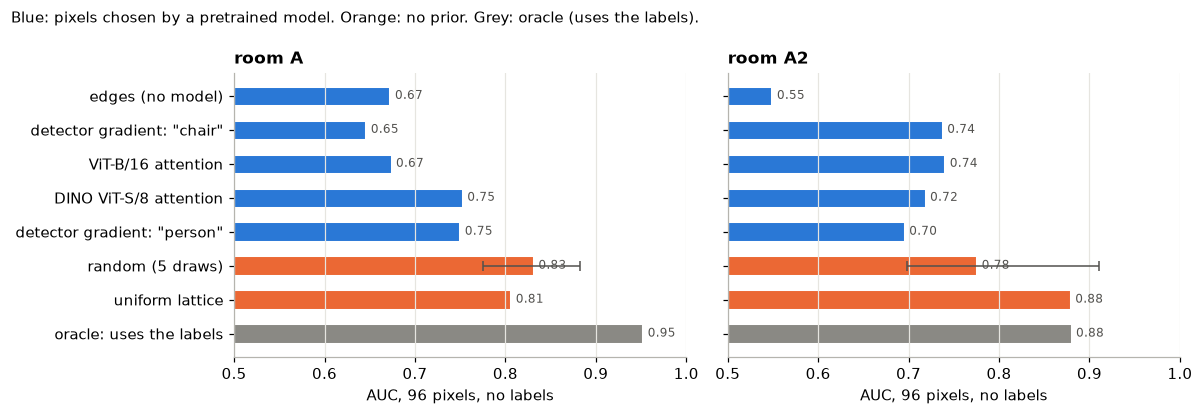

In [5]:
z = zero.groupby(['room', 'prior']).auc.agg(['mean', 'min', 'max']).reset_index()
order = ['discrim', 'uniform', 'random', 'grad_person', 'dino_attn', 'vit_attn', 'grad_chair', 'edges']
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, room in zip(axs, ['A', 'A2']):
    d = z[z.room == room].set_index('prior').loc[order]
    colors = [GRAY if p == 'discrim' else ORANGE if p in ('uniform', 'random') else BLUE for p in order]
    ax.barh([LABEL[p] for p in order], d['mean'], color=colors, height=0.6, edgecolor='white', linewidth=2)
    r = d.loc['random']
    ax.errorbar(r['mean'], LABEL['random'], xerr=[[r['mean'] - r['min']], [r['max'] - r['mean']]], color='#52514e', capsize=3, lw=1)
    for y, v in enumerate(d['mean']):
        ax.text(v + 0.005, y, f'{v:.2f}', va='center', fontsize=8, color='#52514e')
    ax.set_xlim(0.5, 1.0); ax.invert_yaxis(); ax.set_title(f'room {room}', loc='left'); ax.set_xlabel('AUC, 96 pixels, no labels')
    ax.grid(axis='y', visible=False)
fig.suptitle('Blue: pixels chosen by a pretrained model. Orange: no prior. Grey: oracle (uses the labels).', x=0.01, ha='left', fontsize=10)
plt.tight_layout(); plt.show()

**The no-label code.** Bit = pixel more than 15 gray levels from the baseline frame; score = number of bits set. Room A is scored on `training`, `test1`, `test3`; A2 on `training_seats`, `test2` (every 2nd frame).
* Every model prior is below both no-prior codes in both rooms. The best (DINO attention and the "person" gradient in room A, 0.75; ViT attention and the "chair" gradient in A2, 0.74) is 0.05–0.14 below the uniform lattice. Edges are worst (0.55 in A2): edge pixels flip with the smallest camera or lighting change.
* Random pixels vary a lot between draws in A2 (0.70–0.91), and their worst draw (0.70) is below the best model prior there; on average they are ahead of every one.
* The oracle shows the ceiling for 96 single pixels and one baseline frame: 0.95 in A, and in A2 only 0.88, the same as the uniform lattice. In the rearranged room the choice of pixels matters little once they are spread out; the baseline's drift over the sequence limits everything.

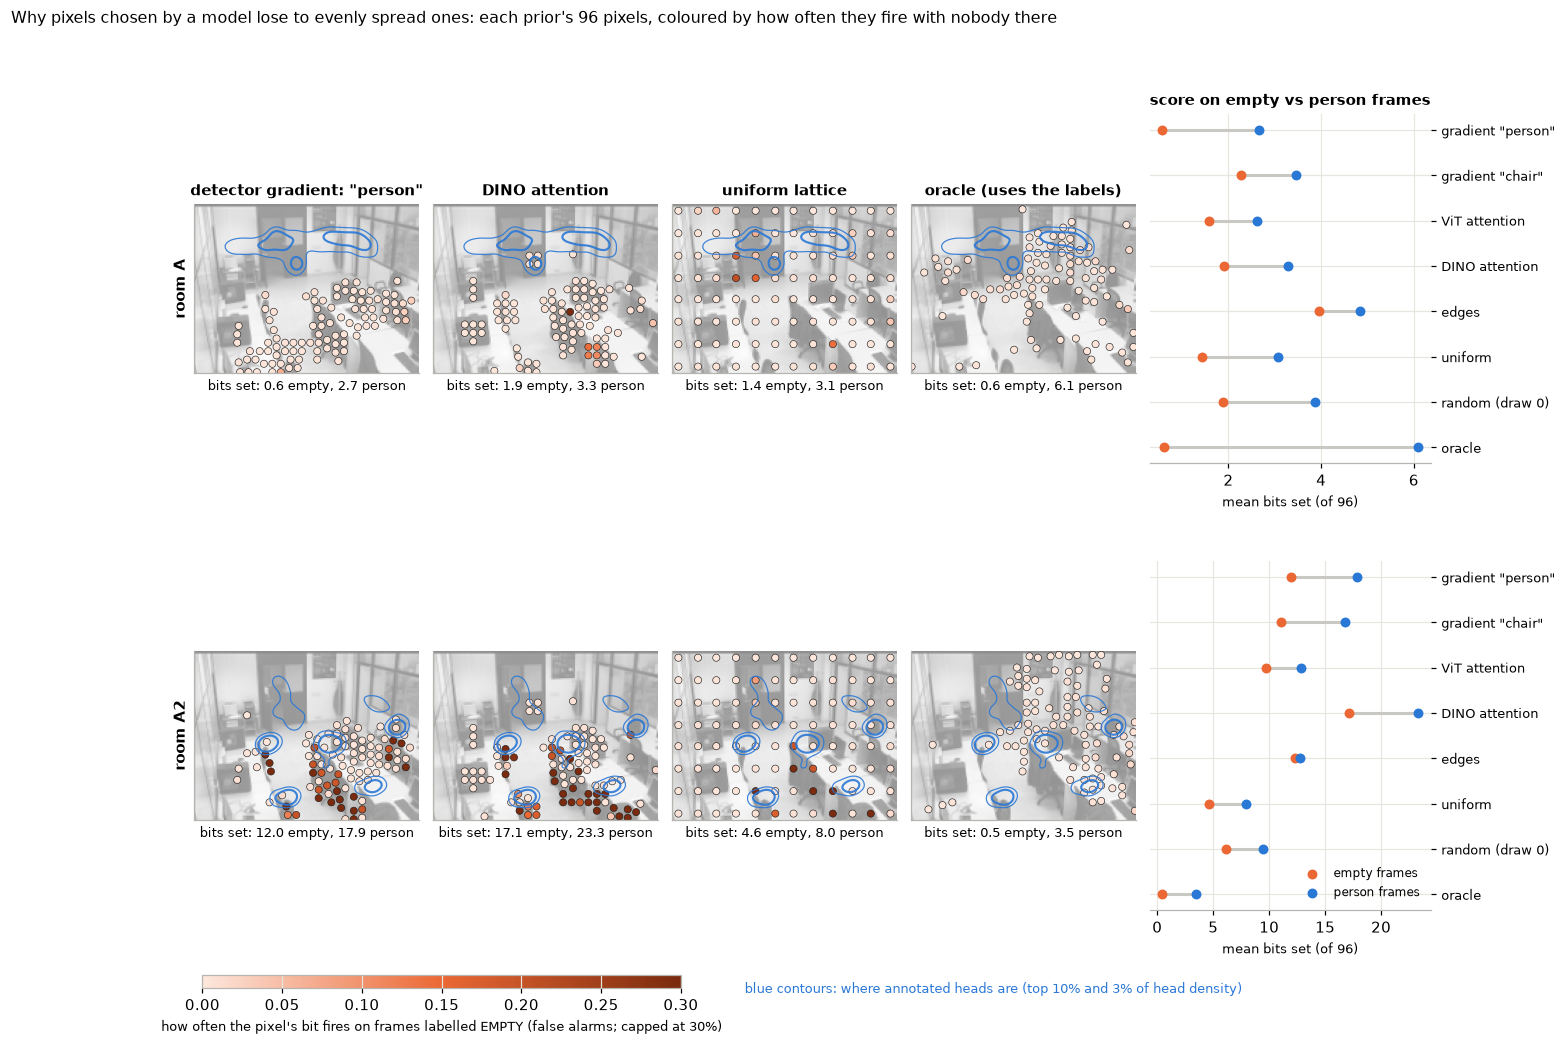

empty       person      
room            A    A2      A    A2
prior                               
grad_person   0.6  12.0    2.7  17.9
grad_chair    2.3  11.1    3.4  16.8
vit_attn      1.6   9.7    2.6  12.9
dino_attn     1.9  17.1    3.3  23.3
edges         4.0  12.3    4.8  12.7
uniform       1.4   4.6    3.1   8.0
random        1.9   6.1    3.9   9.5
discrim       0.6   0.5    6.1   3.5

In [6]:
from semwisp.frames import load_frames
from relevance_prior import ROOMS
frames = load_frames(sum(ROOMS.values(), []))
SHOW = [('grad_person', 'detector gradient: "person"'), ('dino_attn', 'DINO attention'),
        ('uniform', 'uniform lattice'), ('discrim', 'oracle (uses the labels)')]
ALL = ['grad_person', 'grad_chair', 'vit_attn', 'dino_attn', 'edges', 'uniform', 'random', 'discrim']
NAMES = dict(grad_person='gradient "person"', grad_chair='gradient "chair"', vit_attn='ViT attention', dino_attn='DINO attention',
             edges='edges', uniform='uniform', random='random (draw 0)', discrim='oracle')
rates, counts = {}, []
for room, seqs in ROOMS.items():
    base = M[f'{room}/baseline'].astype(np.int16)
    X = np.concatenate([frames[n]['X'][::2][~frames[n]['bad'][::2]] for n in seqs]).astype(np.int16)
    y = np.concatenate([frames[n]['label'][::2][~frames[n]['bad'][::2]] for n in seqs]).astype(bool)
    fire = np.abs(X - base) > 15                       # the tag's bit, for every pixel and frame (as stage_zero)
    rates[room] = (fire[~y].mean(0), fire[y].mean(0))
    for p in ALL:
        px = pick(p if p in ('uniform', 'random') else M[f'{room}/{p}'], 96)
        b = fire[:, px[:, 0], px[:, 1]].sum(1)
        counts.append(dict(room=room, prior=p, empty=b[~y].mean(), person=b[y].mean()))
counts = pd.DataFrame(counts)

fig = plt.figure(figsize=(14.5, 9.4))
gs = fig.add_gridspec(2, len(SHOW) + 1, width_ratios=[1] * len(SHOW) + [1.25], hspace=0.28, wspace=0.06)
from matplotlib.colors import LinearSegmentedColormap
FA = LinearSegmentedColormap.from_list('fa', ['#fde7dd', '#eb6834', '#7a2a0e'])
for r, room in enumerate(['A', 'A2']):
    fa, hit = rates[room]
    base, heads = M[f'{room}/baseline'], M[f'{room}/heads']
    for c, (p, title) in enumerate(SHOW):
        ax = fig.add_subplot(gs[r, c]); ax.set_xticks([]); ax.set_yticks([])
        ax.imshow(base, cmap='gray', vmin=0, vmax=255, alpha=0.45)
        ax.contour(heads, levels=np.quantile(heads, [0.9, 0.97]), colors=BLUE, linewidths=[0.8, 1.4], alpha=0.9)
        px = pick(p if p in ('uniform', 'random') else M[f'{room}/{p}'], 96)
        sc = ax.scatter(px[:, 1], px[:, 0], c=np.clip(fa[px[:, 0], px[:, 1]], 0, 0.3), cmap=FA, vmin=0, vmax=0.3,
                        s=22, edgecolor='#1f1e1c', linewidths=0.4)
        a = counts[(counts.room == room) & (counts.prior == p)].iloc[0]
        ax.set_xlabel(f'bits set: {a['empty']:.1f} empty, {a['person']:.1f} person', fontsize=8.5)
        if r == 0:
            ax.set_title(title, fontsize=9.5)
        if c == 0:
            ax.set_ylabel(f'room {room}', fontsize=10, fontweight='bold')
    # dumbbell: mean bits set on empty vs person frames, every prior
    ax = fig.add_subplot(gs[r, -1])
    d = counts[counts.room == room].set_index('prior').loc[ALL[::-1]]
    yy = np.arange(len(d))
    ax.hlines(yy, d['empty'], d['person'], color='#c9c8c2', lw=2)
    ax.scatter(d['empty'], yy, color=ORANGE, s=30, zorder=3, label='empty frames')
    ax.scatter(d['person'], yy, color=BLUE, s=30, zorder=3, label='person frames')
    ax.set_yticks(yy, [NAMES[p] for p in d.index], fontsize=8.5)
    ax.yaxis.tick_right(); ax.spines[['top', 'left']].set_visible(False); ax.grid(axis='x', color='#e6e5e0')
    ax.set_xlabel('mean bits set (of 96)', fontsize=8.5)
    if r == 0:
        ax.set_title('score on empty vs person frames', fontsize=9.5)
    else:
        ax.legend(frameon=False, fontsize=8, loc='lower right')
cax = fig.add_axes([0.13, 0.035, 0.3, 0.012])
cb = fig.colorbar(sc, cax=cax, orientation='horizontal')
cb.set_label('how often the pixel\'s bit fires on frames labelled EMPTY (false alarms; capped at 30%)', fontsize=8.5)
fig.text(0.47, 0.03, 'blue contours: where annotated heads are (top 10% and 3% of head density)', fontsize=8.5, color=BLUE)
fig.suptitle('Why pixels chosen by a model lose to evenly spread ones: each prior\'s 96 pixels, coloured by how often they fire with nobody there',
             x=0.01, ha='left', fontsize=10.5)
plt.show()
display(counts.pivot(index='prior', columns='room', values=['empty', 'person']).loc[ALL].round(1))


**Why the model pixels lose, in pictures.** Each prior's 96 pixels over the room's baseline frame, coloured by how often that pixel's bit fires on frames labelled *empty*: a false alarm, since nobody is there. Blue contours mark where annotated heads are. On the right, the mean number of bits set (the score) on empty and on person frames, for every prior. The two rooms fail in different ways.
* **Room A: the pixels are in the wrong place.** The model pixels are quiet (pale): the "person" gradient's fire on empty frames least of all, 0.6 bits on average. But they sit on the foreground desks and chairs, while people in room A walk at the back, by the door and windows (the contours). On 40% of the person frames not one of the "person" gradient's 96 bits is set, against 4% for the uniform lattice. DINO puts a few pixels near the door and does a little better.
* **Room A2: the pixels are noisy.** Here the model pixels do overlap the seats where people sit, but many of them are dark orange: on furniture and edges, where a small shift or a change of light moves the gray level past the 15-level tolerance with nobody there. An empty frame sets 10–17 of their bits (the uniform lattice: 4.6), and that count swings widely from frame to frame (standard deviation about 9, against 5.4), so empty and person frames overlap even though the person frames set more bits.
* **The oracle shows what a good pixel looks like**: near where people appear, and almost never firing on an empty frame (0.5–0.6 bits on an empty frame, 3.5–6.1 on a person frame). An evenly spread lattice gets part of the way there by accident: it covers the whole room, and few of its pixels land on edges.

So the attention maps fail at both things a code needs, in different rooms: knowing where people will be (A), and knowing which pixels stay still when nobody is there (A2). The second cannot be seen in a single frame at all.

## 4. With the adaptive loop: does a prior help it start from fewer labels?

In [7]:
rows = []
for f in sorted(RES.glob('online_*.npz')):
    with np.load(f) as zf:
        meta = json.loads(str(zf['meta'])); n = len(zf['label'])
        df = pd.DataFrame({k: zf[k] for k in zf.files if k != 'meta' and zf[k].shape == (n,)})
    first = int(np.flatnonzero(df.reconfig.values)[0]) if df.reconfig.any() else len(df)
    early = df.iloc[first:first + 300]
    rows.append(dict(prior=meta['prior'], bootstrap=meta['bootstrap'], candidates=meta['candidates'],
                     acc_all=balanced_accuracy(df), acc_first300=balanced_accuracy(early) if len(early) >= 100 else np.nan,
                     bytes=float(df.up_bytes.mean()), full_rate=float(df.explored.mean())))
online = pd.DataFrame(rows)
display(online.pivot_table(index='prior', columns='bootstrap', values=['acc_first300', 'acc_all', 'bytes']).round(3))

acc_all               acc_first300                   bytes  \
bootstrap       25     50     200          25     50     200       25    
prior                                                                    
dino_attn     0.783  0.781  0.814        0.778  0.778  0.746  8808.975   
edges         0.778  0.778  0.769        0.891  0.891  0.744  8820.352   
grad_chair    0.796  0.796  0.796        0.879  0.879  0.757  8555.743   
grad_person   0.773  0.773  0.799        0.871  0.871  0.739  8724.708   
lattice       0.817  0.817  0.805        0.866  0.866  0.817  7113.913   
random        0.825  0.825  0.798        0.909  0.909  0.821  8071.378   
uniform       0.827  0.827  0.809        0.899  0.899  0.855  7761.610   
vit_attn      0.785  0.785  0.782        0.879  0.879  0.827  8341.721   

                                  
bootstrap         50         200  
prior                             
dino_attn    8639.993  10406.848  
edges        8820.352   8870.622  
grad_chair   8555.743   8555.222  
grad_person  8724.708  10637.586  
lattice      7113.913   8572.119  
random       8071.378   8667.865  
uniform      7761.610   7952.582  
vit_attn     8341.721   8943.840

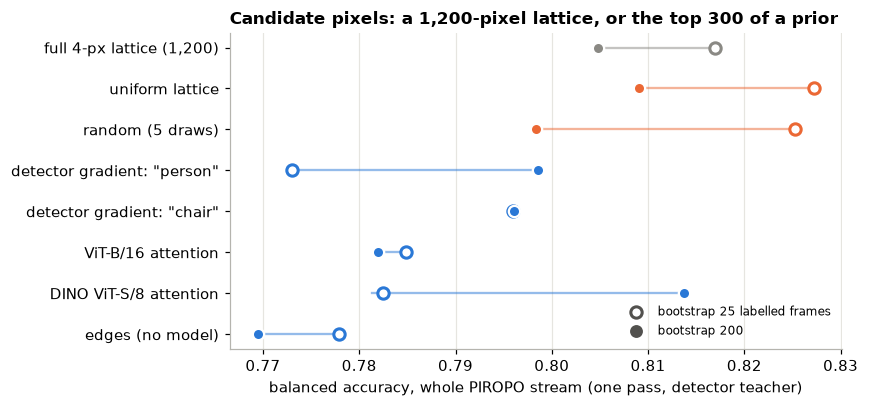

In [8]:
order = ['lattice', 'uniform', 'random', 'grad_person', 'grad_chair', 'vit_attn', 'dino_attn', 'edges']
fig, ax = plt.subplots(figsize=(8, 3.8))
for y, p in enumerate(order):
    d = online[online.prior == p].set_index('bootstrap')
    color = GRAY if p == 'lattice' else ORANGE if p in ('uniform', 'random') else BLUE
    ax.plot([d.acc_all.min(), d.acc_all.max()], [y, y], color=color, lw=1.5, alpha=0.5)
    ax.scatter(d.acc_all[25], y, s=55, facecolor='white', edgecolor=color, linewidth=2, zorder=3)
    ax.scatter(d.acc_all[200], y, s=55, color=color, edgecolor='white', linewidth=1.5, zorder=3)
ax.set_yticks(range(len(order)), [LABEL[p] for p in order]); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.scatter([], [], s=55, facecolor='white', edgecolor='#52514e', linewidth=2, label='bootstrap 25 labelled frames')
ax.scatter([], [], s=55, color='#52514e', label='bootstrap 200')
ax.legend(frameon=False, fontsize=8, loc='lower right'); ax.set_xlabel('balanced accuracy, whole PIROPO stream (one pass, detector teacher)')
ax.set_title('Candidate pixels: a 1,200-pixel lattice, or the top 300 of a prior', loc='left')
plt.tight_layout(); plt.show()

**The online loop.** Open circles: 25-frame bootstrap; filled: 200 (bootstrap 50 gives the same runs as 25, because the first code also waits for 10 frames of each class). The candidate set is fixed for the whole stream, taken from room A's baseline.
* No prior beats the no-prior sets. 300 uniform or random pixels give 0.80–0.83, the full 1,200-pixel lattice 0.81–0.82, the model priors 0.77–0.81 (DINO attention's 0.81 at bootstrap 200 is the only one level with the rest).
* The learner picks its 96 bits from the candidates, so a candidate set mostly needs to *contain* good pixels; packing the 300 onto furniture leaves out the floor and the back of the room.
* The table also gives accuracy over the first 300 queries after the first code, but those stretches start at different points in the stream for different bootstraps, so they are not comparable across columns.

## What this means for the idea
* **Relevance on one empty frame measures salience, not usefulness.** The pretrained models know what objects are in the room; a presence code needs to know where a person will change pixels that otherwise stay still. That second thing depends on lighting, camera noise and where people walk, which one frame does not show.
* **Where it might still help.** The "person" map in A2 does carry real information about where people sit. Used as a *weight* on top of a coverage constraint (spread the pixels, then prefer the prior's areas), or to rank candidates for an online learner that also measures stability, it might add something; used alone to choose pixels it hurts.
* **What the earlier discussion predicted and this confirms**: an affordance model (floor and seat geometry, or a generative model placing people in the scene) is the right kind of prior for "where can a person appear", and stability has to come from data. Neither was tested here: they need models (depth, segmentation, inpainting) that are not installed.

## Limits
* One room in two layouts, one baseline frame each, one detector and two ViTs; settings (15-level threshold, 6-pixel spacing, SmoothGrad with 16 samples, last-layer attention averaged over heads) chosen once. Attention rollout, per-head maps, Grad-CAM or a text-conditioned model (OWL-ViT, CLIP) could give different maps.
* The no-label code compares with a single baseline frame; a running background would help every prior equally.
* The "chair" query is only used to show that the maps change with the query; there are no chair labels to test a chair code.